# Actor Genre Clustering Analysis

This notebook constructs an actor-by-genre dataset from raw IMDb movie data, normalizes the actor profiles, selects a value for k using the elbow method, clusters actors using K-Means, and analyzes the resulting clusters.

In [ ]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

In [ ]:
movies = []

with open("imdb_movies_2000to2022.prolific.json", "r") as infile:
    for line in infile:
        movies.append(json.loads(line))

print("Number of movies:", len(movies))

Number of movies: 20620


In [ ]:
actor_name_map = {}

for movie in movies:
    for actor_id, actor_name in movie["actors"]:
        actor_name_map[actor_id] = actor_name

print("Number of actors:", len(actor_name_map))

Number of actors: 33609


In [ ]:
actor_genre_counts = {}

for movie in movies:
    genres = movie["genres"]

    for actor_id, actor_name in movie["actors"]:

        if actor_id not in actor_genre_counts:
            actor_genre_counts[actor_id] = {}

        for genre in genres:
            actor_genre_counts[actor_id][genre] = (
                actor_genre_counts[actor_id].get(genre, 0) + 1
            )

In [ ]:
actor_genre_df = pd.DataFrame.from_dict(
    actor_genre_counts,
    orient="index"
).fillna(0)

actor_genre_df.index.name = "actor_id"

actor_genre_df.head()

,Comedy,Fantasy,Romance,Drama,Mystery,Thriller,Action,Biography,Crime,War,...,Horror,Documentary,Sport,News,Family,Music,,Western,Short,Reality-TV
actor_id,,,,,,,,,,,,,,,,,,,,,
nm0000212,7.0,1.0,6.0,6.0,1.0,2.0,1.0,1.0,2.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
nm0413168,7.0,3.0,5.0,12.0,5.0,2.0,14.0,4.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
nm0000630,8.0,2.0,6.0,14.0,2.0,3.0,4.0,5.0,1.0,1.0,...,3.0,7.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
nm0005227,10.0,1.0,2.0,2.0,0.0,1.0,1.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0
nm0864851,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
print("Shape:", actor_genre_df.shape)
print()
print("Genres:")
print(actor_genre_df.columns.tolist())

Shape: (33609, 25)

Genres:
['Comedy', 'Fantasy', 'Romance', 'Drama', 'Mystery', 'Thriller', 'Action', 'Biography', 'Crime', 'War', 'Adventure', 'Sci-Fi', 'Animation', 'Musical', 'History', 'Horror', 'Documentary', 'Sport', 'News', 'Family', 'Music', '', 'Western', 'Short', 'Reality-TV']


In [ ]:
actor_genre_df = actor_genre_df.loc[
    :,
    ~actor_genre_df.columns.str.contains("^Unnamed")
]

actor_genre_df.shape

(33609, 25)

In [ ]:
row_sums = actor_genre_df.sum(axis=1)

actor_genre_df = actor_genre_df[
    row_sums > 0
]

actor_genre_df.shape

(33609, 25)

In [ ]:
actor_genre_df.to_csv(
    "constructed_actor_genre_matrix.csv"
)

print("Dataset saved.")

Dataset saved.


In [ ]:
normalized_actor_genre_df = actor_genre_df.div(
    actor_genre_df.sum(axis=1),
    axis=0
)

normalized_actor_genre_df.head()

,Comedy,Fantasy,Romance,Drama,Mystery,Thriller,Action,Biography,Crime,War,...,Horror,Documentary,Sport,News,Family,Music,,Western,Short,Reality-TV
actor_id,,,,,,,,,,,,,,,,,,,,,
nm0000212,0.250000,0.035714,0.214286,0.214286,0.035714,0.071429,0.035714,0.035714,0.071429,0.035714,...,0.000000,0.000000,0.000000,0.000000,0.00,0.0,0.0,0.0,0.0,0.0
nm0413168,0.081395,0.034884,0.058140,0.139535,0.058140,0.023256,0.162791,0.046512,0.069767,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00,0.0,0.0,0.0,0.0,0.0
nm0000630,0.112676,0.028169,0.084507,0.197183,0.028169,0.042254,0.056338,0.070423,0.014085,0.014085,...,0.042254,0.098592,0.042254,0.014085,0.00,0.0,0.0,0.0,0.0,0.0
nm0005227,0.400000,0.040000,0.080000,0.080000,0.000000,0.040000,0.040000,0.000000,0.000000,0.000000,...,0.040000,0.000000,0.040000,0.000000,0.08,0.0,0.0,0.0,0.0,0.0
nm0864851,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.333333,0.000000,0.000000,0.000000,0.00,0.0,0.0,0.0,0.0,0.0


In [ ]:
normalized_actor_genre_df.sum(axis=1).head(10)

,0
actor_id,
nm0000212,1.0
nm0413168,1.0
nm0000630,1.0
nm0005227,1.0
nm0864851,1.0
nm0828288,1.0
nm0933983,1.0
nm0329491,1.0
nm0000417,1.0


In [ ]:
k_values = range(2, 16)
inertia_values = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(normalized_actor_genre_df)

    inertia_values.append(
        model.inertia_
    )

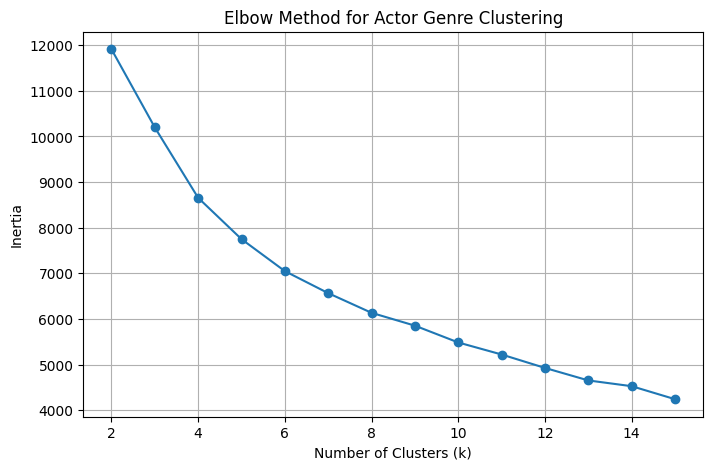

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Actor Genre Clustering")

plt.grid()

plt.savefig(
    "actor_cluster_elbow.png",
    bbox_inches="tight"
)

plt.show()

In [ ]:
k = 8

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(
    normalized_actor_genre_df
)

In [ ]:
cluster_df = pd.DataFrame(
    {
        "cluster": cluster_labels
    },
    index=normalized_actor_genre_df.index
)

cluster_df.head()

,cluster
actor_id,
nm0000212,0
nm0413168,2
nm0000630,7
nm0005227,0
nm0864851,4


In [ ]:
cluster_sizes = (
    cluster_df["cluster"]
    .value_counts()
    .sort_index()
)

cluster_sizes

,count
cluster,
0,6418
1,3960
2,4619
3,1652
4,5965
5,1998
6,975
7,8022


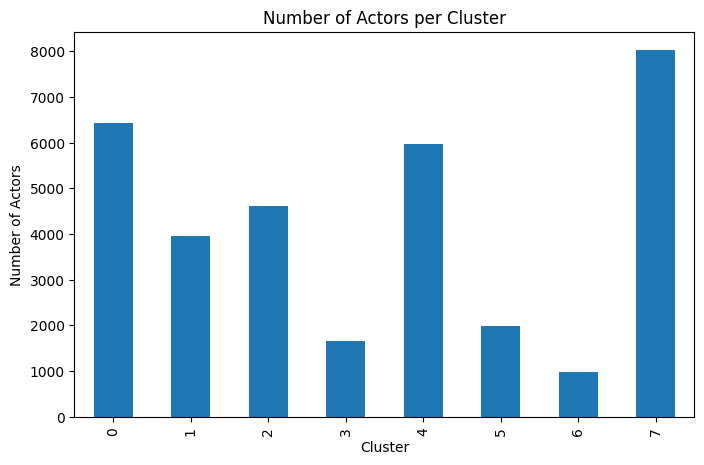

In [ ]:
plt.figure(figsize=(8, 5))

cluster_sizes.plot(
    kind="bar"
)

plt.xlabel("Cluster")
plt.ylabel("Number of Actors")
plt.title("Number of Actors per Cluster")

plt.savefig(
    "actor_cluster_sizes.png",
    bbox_inches="tight"
)

plt.show()

In [ ]:
cluster_centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=normalized_actor_genre_df.columns
)

cluster_centers

,Comedy,Fantasy,Romance,Drama,Mystery,Thriller,Action,Biography,Crime,War,...,Horror,Documentary,Sport,News,Family,Music,,Western,Short,Reality-TV
0,0.379609,1.834981e-02,0.126074,0.212993,0.010396,0.020888,0.021090,7.530826e-03,3.009658e-02,1.049491e-03,...,0.043924,5.196000e-03,7.362133e-03,1.638908e-05,3.129137e-02,1.167759e-02,1.702511e-03,2.091637e-03,2.106549e-06,7.423078e-06
1,0.000694,6.313131e-05,0.000278,0.997927,0.000099,0.000415,0.000126,5.050505e-05,6.313131e-05,-4.510281e-17,...,0.000063,1.252470e-15,6.313131e-05,6.667843e-18,9.469697e-05,3.920475e-16,5.342948e-16,4.198031e-16,1.785545e-18,1.055742e-17
2,0.057701,1.661079e-02,0.013358,0.125452,0.006863,0.081839,0.427999,4.608182e-03,1.105170e-01,6.653199e-03,...,0.031977,1.358135e-03,4.697876e-03,5.291918e-05,6.536310e-03,1.256846e-03,3.871482e-04,4.847830e-03,4.912791e-19,1.253609e-17
3,0.006311,3.295232e-04,0.000074,0.002771,0.001362,0.008811,0.001241,-1.196959e-16,1.080187e-03,-4.250073e-17,...,0.974993,5.779649e-04,2.931683e-16,1.165517e-18,3.026634e-04,1.032160e-16,2.450133e-04,2.017756e-04,7.555534e-19,3.026634e-05
4,0.029925,3.312570e-02,0.012813,0.022022,0.066032,0.151169,0.028319,1.241873e-02,3.490973e-02,9.385380e-03,...,0.177577,6.688375e-02,2.661213e-02,4.209036e-04,5.732313e-02,5.540569e-03,6.264235e-02,2.268020e-02,-2.205674e-18,6.704660e-04
5,0.993242,6.673340e-04,0.000056,0.001059,0.000389,0.000617,0.000334,1.668335e-04,1.668335e-04,-4.336809e-17,...,0.001390,6.673340e-05,6.435006e-04,2.805373e-18,-7.979728e-16,1.668335e-04,1.668335e-04,1.882175e-16,1.063873e-18,-2.602085e-18
6,0.000889,1.734723e-16,0.000342,0.003087,0.000462,0.987082,0.001377,9.540979e-17,-4.510281e-16,-4.076600e-17,...,0.005385,-1.734723e-17,1.214306e-17,-2.195509e-18,-2.810252e-16,-7.979728e-17,1.006140e-16,-1.040834e-17,-2.507218e-19,-2.154852e-18
7,0.038579,1.918958e-02,0.079021,0.390704,0.050032,0.109511,0.026948,2.827095e-02,7.680889e-02,8.740608e-03,...,0.047413,4.782852e-03,1.215919e-02,7.987267e-05,2.582117e-02,1.488233e-02,1.398039e-03,4.457906e-03,1.244710e-04,1.772671e-17


In [ ]:
for cluster_id in range(k):

    print("Cluster", cluster_id)

    top_genres = (
        cluster_centers
        .loc[cluster_id]
        .sort_values(ascending=False)
        .head(5)
    )

    print(top_genres)
    print()

Cluster 0
Comedy       0.379609
Drama        0.212993
Romance      0.126074
Horror       0.043924
Adventure    0.033531
Name: 0, dtype: float64

Cluster 1
Drama       0.997927
Comedy      0.000694
Thriller    0.000415
Romance     0.000278
Action      0.000126
Name: 1, dtype: float64

Cluster 2
Action      0.427999
Drama       0.125452
Crime       0.110517
Thriller    0.081839
Comedy      0.057701
Name: 2, dtype: float64

Cluster 3
Horror      0.974993
Thriller    0.008811
Comedy      0.006311
Drama       0.002771
Sci-Fi      0.001468
Name: 3, dtype: float64

Cluster 4
Horror         0.177577
Thriller       0.151169
Sci-Fi         0.089359
Documentary    0.066884
Mystery        0.066032
Name: 4, dtype: float64

Cluster 5
Comedy     0.993242
Horror     0.001390
Drama      0.001059
Fantasy    0.000667
Sport      0.000644
Name: 5, dtype: float64

Cluster 6
Thriller     0.987082
Horror       0.005385
Drama        0.003087
Action       0.001377
Adventure    0.001026
Name: 6, dtype: float64



In [ ]:
for cluster_id in range(k):

    print("Cluster", cluster_id)

    actor_ids = cluster_df[
        cluster_df["cluster"] == cluster_id
    ].index

    sample_ids = actor_ids[:10]

    for actor_id in sample_ids:
        print(
            actor_id,
            "-",
            actor_name_map.get(actor_id, "Unknown")
        )

    print()

Cluster 0
nm0000212 - Meg Ryan
nm0005227 - Breckin Meyer
nm0412917 - Jaaved Jaaferi
nm1142237 - Rosa Navarra
nm0321320 - Rudy Giuliani
nm0001123 - Dom DeLuise
nm0269451 - Kenneth Favre
nm0803374 - Gerry Sanseviero
nm1315804 - Todo Segalla
nm0803138 - Antonia Sisti

Cluster 1
nm0000588 - Martha Plimpton
nm0762191 - Nick Sandow
nm0404269 - Eleanor Hutchins
nm0311297 - Karl Geary
nm0411581 - Maia Morgenstern
nm0001732 - Cybill Shepherd
nm1514871 - Kristian Bernard
nm0001864 - Noah Wyle
nm0319171 - Daniel Gillies
nm7234397 - Mylarah Silverne

Cluster 2
nm0413168 - Hugh Jackman
nm0923529 - Justin Whalin
nm0006763 - Jackie Shroff
nm0200057 - Phil Daniels
nm0262635 - Chris Evans
nm0089217 - Orlando Bloom
nm0000129 - Tom Cruise
nm0000609 - Ving Rhames
nm0735442 - Michelle Rodriguez
nm0184392 - Martin Kove

Cluster 3
nm0541932 - Tyler Mane
nm0780133 - Angus Scrimm
nm0499614 - Ari Lehman
nm3527272 - Jennifer Nangle
nm2826608 - Alan Maxson
nm2766218 - Julie Anne Prescott
nm5560956 - Sheri Davis
n

In [ ]:
actor_total_appearances = actor_genre_df.sum(axis=1)

for cluster_id in range(k):

    print("\nCluster", cluster_id)

    actor_ids = cluster_df[
        cluster_df["cluster"] == cluster_id
    ].index

    ranked_actors = (
        actor_total_appearances
        .loc[actor_ids]
        .sort_values(ascending=False)
        .head(10)
    )

    for actor_id in ranked_actors.index:
        print(
            actor_id,
            "-",
            actor_name_map.get(actor_id, "Unknown")
        )


Cluster 0
nm0005351 - Ryan Reynolds
nm0000215 - Susan Sarandon
nm0005562 - Owen Wilson
nm0000147 - Colin Firth
nm0004266 - Anne Hathaway
nm0000190 - Matthew McConaughey
nm0000285 - Alec Baldwin
nm1289434 - Emily Blunt
nm0001057 - Toni Collette
nm0316079 - Paul Giamatti

Cluster 1
nm3956954 - T.C. Stallings
nm0791851 - Robert Shepherd
nm1829290 - Kris Rey
nm2959880 - Colin Morgan
nm4101208 - Ben Rosenfield
nm4951025 - Stacey Bradshaw
nm0762191 - Nick Sandow
nm6910787 - Michael Everett Johnson
nm3630119 - Trevor Jackson
nm1002662 - Harry Eden

Cluster 2
nm0001803 - Danny Trejo
nm0000115 - Nicolas Cage
nm0000246 - Bruce Willis
nm0000168 - Samuel L. Jackson
nm0474774 - Akshay Kumar
nm0000553 - Liam Neeson
nm0001595 - Michael Paré
nm0425005 - Dwayne Johnson
nm0000242 - Mark Wahlberg
nm0005458 - Jason Statham

Cluster 3
nm3025400 - Shawn C. Phillips
nm2766218 - Julie Anne Prescott
nm8279086 - Mike Ferguson
nm8099914 - Ken May
nm3527272 - Jennifer Nangle
nm2794671 - Lee Bane
nm0499614 - Ari 

In [ ]:
summary_rows = []

for cluster_id in range(k):

    top_genres = (
        cluster_centers
        .loc[cluster_id]
        .sort_values(ascending=False)
        .head(3)
    )

    summary_rows.append({
        "Cluster": cluster_id,
        "Top Genre 1": top_genres.index[0],
        "Top Genre 1 Weight": top_genres.iloc[0],
        "Top Genre 2": top_genres.index[1],
        "Top Genre 2 Weight": top_genres.iloc[1],
        "Top Genre 3": top_genres.index[2],
        "Top Genre 3 Weight": top_genres.iloc[2],
        "Number of Actors": cluster_sizes.loc[cluster_id]
    })

cluster_summary_df = pd.DataFrame(
    summary_rows
)

cluster_summary_df

,Cluster,Top Genre 1,Top Genre 1 Weight,Top Genre 2,Top Genre 2 Weight,Top Genre 3,Top Genre 3 Weight,Number of Actors
0,0,Comedy,0.379609,Drama,0.212993,Romance,0.126074,6418
1,1,Drama,0.997927,Comedy,0.000694,Thriller,0.000415,3960
2,2,Action,0.427999,Drama,0.125452,Crime,0.110517,4619
3,3,Horror,0.974993,Thriller,0.008811,Comedy,0.006311,1652
4,4,Horror,0.177577,Thriller,0.151169,Sci-Fi,0.089359,5965
5,5,Comedy,0.993242,Horror,0.001390,Drama,0.001059,1998
6,6,Thriller,0.987082,Horror,0.005385,Drama,0.003087,975
7,7,Drama,0.390704,Thriller,0.109511,Romance,0.079021,8022


In [ ]:
cluster_summary_df.to_csv(
    "cluster_summary.csv",
    index=False
)

print("Cluster summary saved.")

Cluster summary saved.


In [ ]:
print(
    "Number of unique clusters:",
    cluster_df["cluster"].nunique()
)

print(
    "Expected clusters:",
    k
)

Number of unique clusters: 8
Expected clusters: 8


In [ ]:
print(
    "Actors in normalized dataset:",
    len(normalized_actor_genre_df)
)

print(
    "Actors assigned to clusters:",
    len(cluster_df)
)

Actors in normalized dataset: 33609
Actors assigned to clusters: 33609


In [ ]:
cluster_assignments = cluster_df.copy()

cluster_assignments["actor_name"] = [
    actor_name_map.get(actor_id, "Unknown")
    for actor_id in cluster_assignments.index
]

cluster_assignments.to_csv(
    "actor_cluster_assignments.csv"
)

cluster_assignments.head()

,cluster,actor_name
actor_id,,
nm0000212,0,Meg Ryan
nm0413168,2,Hugh Jackman
nm0000630,7,Liev Schreiber
nm0005227,0,Breckin Meyer
nm0864851,4,Kenneth Tobey


In [ ]:
actor_genre_df.to_csv(
    "constructed_actor_genre_matrix.csv"
)

In [ ]:
cluster_summary_df.to_csv(
    "cluster_summary.csv",
    index=False
)

In [ ]:
plt.savefig(
    "actor_cluster_elbow.png",
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.savefig(
    "actor_cluster_sizes.png",
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>